In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Put superstore.csv in the same folder as this notebook.
DATA_PATH = Path("C:\\Users\\ADMIN\\Desktop\\Assesment\\VirtuBox Infotech Data Analyst Assesment - Processed Data.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH.resolve()}\n"
        "Move superstore.csv into the same folder as this notebook, "
        "or change DATA_PATH to the full path of your CSV."
    )

df = pd.read_csv(DATA_PATH, encoding="utf-8-sig")
df.columns = df.columns.str.strip()

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")
print("\nColumn names:")
print(df.columns.tolist())
display(df.head())

Rows: 51,290
Columns: 30

Column names:
['Category', 'City', 'Country', 'Customer.ID', 'Customer.Name', 'Discount', 'Market', 'Record Count', 'Order.Date', 'Order.ID', 'Order.Priority', 'Product.ID', 'Product.Name', 'Profit', 'Quantity', 'Region', 'Row.ID', 'Sales', 'Segment', 'Ship.Date', 'Ship.Mode', 'Shipping.Cost', 'State', 'Sub.Category', 'Year', 'Market2', 'weeknum', 'Profit Margin', 'Shipping Days', 'Order Year']


,Category,City,Country,Customer.ID,Customer.Name,Discount,Market,Record Count,Order.Date,Order.ID,...,Ship.Mode,Shipping.Cost,State,Sub.Category,Year,Market2,weeknum,Profit Margin,Shipping Days,Order Year
0,Office Supplies,Los Angeles,United States,LS-172304,Lycoris Saunders,0.0,US,1,2011-01-07 00:00:00,CA-2011-130813,...,Second Class,4.37,California,Paper,2011,North America,2,0.491116,2,2011
1,Office Supplies,Los Angeles,United States,MV-174854,Mark Van Huff,0.0,US,1,2011-01-21 00:00:00,CA-2011-148614,...,Standard Class,0.94,California,Paper,2011,North America,4,0.489095,5,2011
2,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,1,2011-08-05 00:00:00,CA-2011-118962,...,Standard Class,1.81,California,Paper,2011,North America,32,0.468657,4,2011
3,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,1,2011-08-05 00:00:00,CA-2011-118962,...,Standard Class,4.59,California,Paper,2011,North America,32,0.479827,4,2011
4,Office Supplies,Los Angeles,United States,AP-109154,Arthur Prichep,0.0,US,1,2011-09-29 00:00:00,CA-2011-146969,...,Standard Class,1.32,California,Paper,2011,North America,40,0.518400,4,2011


In [ ]:
# Convert date fields if present
for col in ["Order.Date", "Ship.Date"]:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce")

# Convert important numeric columns if present
numeric_cols = [
    "Sales", "Profit", "Discount", "Quantity",
    "Shipping.Cost", "Profit Margin", "Shipping Days"
]
for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Create useful calculated fields if they do not already exist
if "Profit Margin" not in df.columns and {"Profit", "Sales"}.issubset(df.columns):
    df["Profit Margin"] = df["Profit"] / df["Sales"].replace(0, np.nan)

if "Shipping Days" not in df.columns and {"Order.Date", "Ship.Date"}.issubset(df.columns):
    df["Shipping Days"] = (df["Ship.Date"] - df["Order.Date"]).dt.days

if "Order Year" not in df.columns and "Order.Date" in df.columns:
    df["Order Year"] = df["Order.Date"].dt.year

print("Missing cells:", int(df.isna().sum().sum()))
print("Exact duplicate rows:", int(df.duplicated().sum()))
if "Row.ID" in df.columns:
    print("Duplicate Row.ID values:", int(df["Row.ID"].duplicated().sum()))

display(df[["Sales", "Profit", "Discount"]].describe())


Missing cells: 1
Exact duplicate rows: 0
Duplicate Row.ID values: 0


,Sales,Profit,Discount
count,51290.000000,51290.000000,51290.000000
mean,246.498440,28.610982,0.142908
std,487.567175,174.340972,0.212280
min,0.000000,-6599.978000,0.000000
25%,31.000000,0.000000,0.000000
50%,85.000000,9.240000,0.000000
75%,251.000000,36.810000,0.200000
max,22638.000000,8399.976000,0.850000


Chart 1 — Sales and profit by category

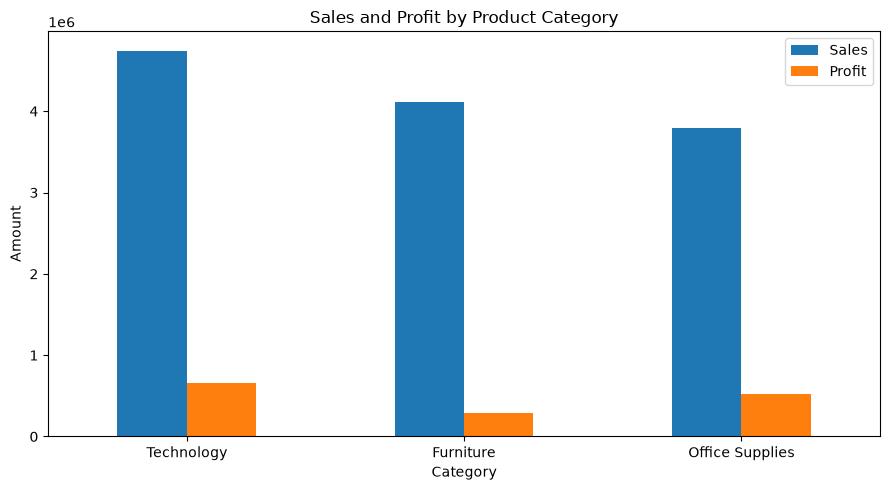

,Sales,Profit
Category,,
Technology,4744691,663778.73318
Furniture,4110884,285204.72380
Office Supplies,3787330,518473.83430


In [ ]:
required = {"Category", "Sales", "Profit"}
missing = required - set(df.columns)
if missing:
    print("Cannot create chart: missing columns", missing)
else:
    category_summary = df.groupby("Category")[["Sales", "Profit"]].sum().sort_values("Sales", ascending=False)
    ax = category_summary.plot(kind="bar", figsize=(9, 5))
    ax.set_title("Sales and Profit by Product Category")
    ax.set_xlabel("Category")
    ax.set_ylabel("Amount")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
    display(category_summary)


Chart 2 — Profit by region

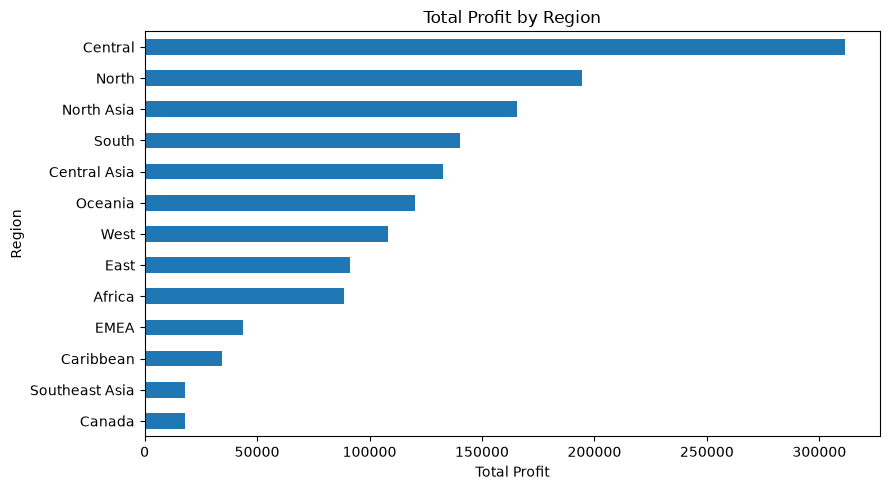

,Total Profit
Region,
Canada,17817.39000
Southeast Asia,17852.32900
Caribbean,34571.32104
EMEA,43897.97100
Africa,88871.63100
East,91522.78000
West,108418.44890
Oceania,120089.11200
Central Asia,132480.18700


In [ ]:
required = {"Region", "Profit"}
missing = required - set(df.columns)
if missing:
    print("Cannot create chart: missing columns", missing)
else:
    region_profit = df.groupby("Region")["Profit"].sum().sort_values()
    ax = region_profit.plot(kind="barh", figsize=(9, 5))
    ax.set_title("Total Profit by Region")
    ax.set_xlabel("Total Profit")
    ax.set_ylabel("Region")
    plt.tight_layout()
    plt.show()
    display(region_profit.to_frame("Total Profit"))


Chart 3 — Profit by sub-category

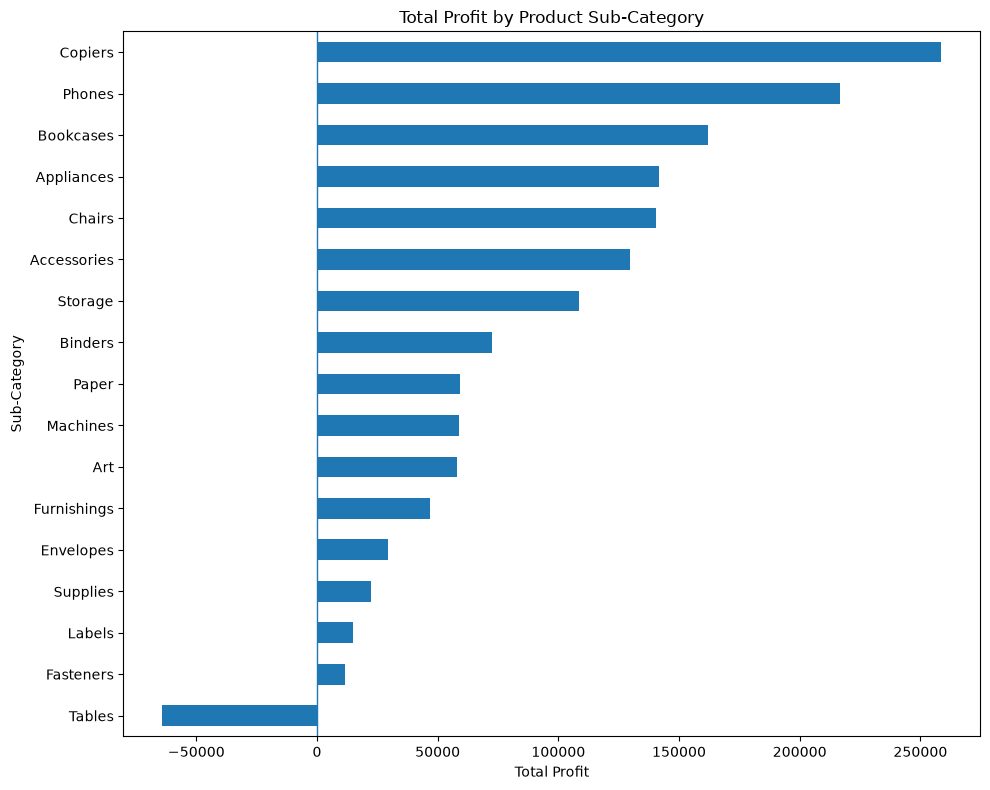

,Total Profit
Sub.Category,
Tables,-64083.38870
Fasteners,11525.42410
Labels,15010.51200
Supplies,22583.26310
Envelopes,29601.11630
Furnishings,46967.42550
Art,57953.91090
Machines,58867.87300
Paper,59207.68270


In [ ]:
required = {"Sub.Category", "Profit"}
missing = required - set(df.columns)
if missing:
    print("Cannot create chart: missing columns", missing)
else:
    sub_profit = df.groupby("Sub.Category")["Profit"].sum().sort_values()
    ax = sub_profit.plot(kind="barh", figsize=(10, 8))
    ax.axvline(0, linewidth=1)
    ax.set_title("Total Profit by Product Sub-Category")
    ax.set_xlabel("Total Profit")
    ax.set_ylabel("Sub-Category")
    plt.tight_layout()
    plt.show()
    display(sub_profit.to_frame("Total Profit"))


Chart 4 — Yearly sales and profit trend

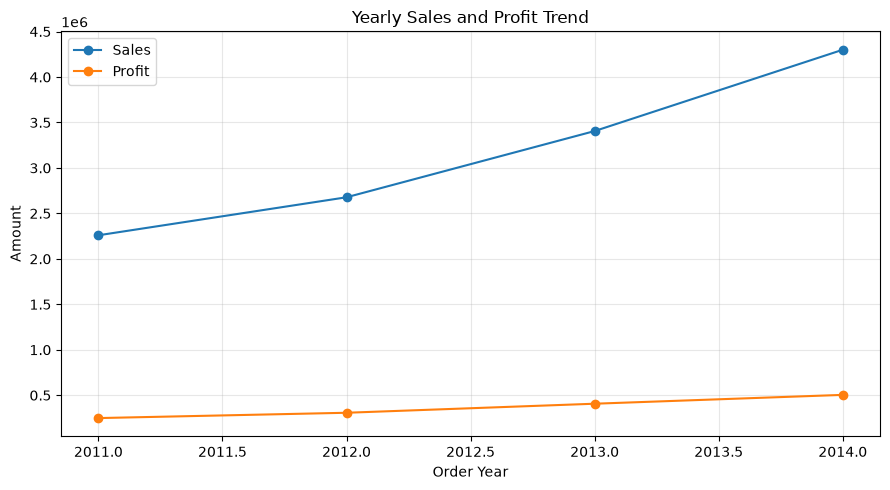

,Sales,Profit
Order Year,,
2011,2259511,248940.81154
2012,2677493,307415.27910
2013,3405860,406935.23018
2014,4300041,504165.97046


In [ ]:
if "Order Year" not in df.columns and "Order.Date" in df.columns:
    df["Order Year"] = pd.to_datetime(df["Order.Date"], errors="coerce").dt.year

required = {"Order Year", "Sales", "Profit"}
missing = required - set(df.columns)
if missing:
    print("Cannot create chart: missing columns", missing)
else:
    yearly = df.groupby("Order Year")[["Sales", "Profit"]].sum().sort_index()
    ax = yearly.plot(kind="line", marker="o", figsize=(9, 5))
    ax.set_title("Yearly Sales and Profit Trend")
    ax.set_xlabel("Order Year")
    ax.set_ylabel("Amount")
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    display(yearly)


Chart 5 — Aggregate profit margin by discount level

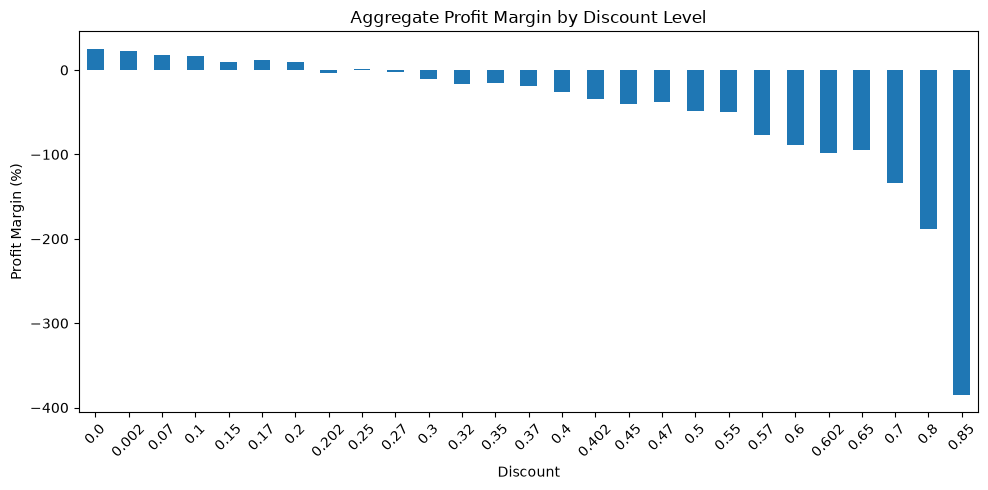

,Total_Sales,Total_Profit,Records,Profit_Margin_Pct
Discount,,,,
0.000,6992734,1.770695e+06,29009,25.321931
0.002,261395,5.797658e+04,461,22.179683
0.070,121620,2.114850e+04,150,17.389001
0.100,1579618,2.590642e+05,4068,16.400432
0.150,306037,2.737590e+04,541,8.945292
0.170,247404,2.816307e+04,735,11.383435
0.200,1203855,1.177159e+05,4998,9.778243
0.202,16213,-5.952727e+02,41,-3.671577
0.250,88063,8.005875e+02,198,0.909108


In [ ]:
required = {"Discount", "Sales", "Profit"}
missing = required - set(df.columns)
if missing:
    print("Cannot create chart: missing columns", missing)
else:
    discount_summary = df.groupby("Discount").agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Records=("Profit", "count")
    )
    discount_summary["Profit_Margin_Pct"] = (
        discount_summary["Total_Profit"] /
        discount_summary["Total_Sales"].replace(0, np.nan)
    ) * 100
    discount_summary = discount_summary.sort_index()
    ax = discount_summary["Profit_Margin_Pct"].plot(kind="bar", figsize=(10, 5))
    ax.set_title("Aggregate Profit Margin by Discount Level")
    ax.set_xlabel("Discount")
    ax.set_ylabel("Profit Margin (%)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
    display(discount_summary)


Chart 6 — Sales and profit by customer segment

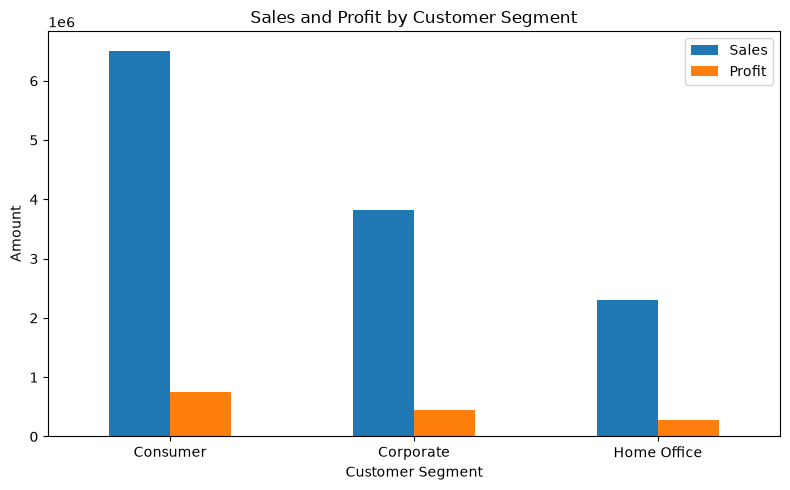

,Sales,Profit
Segment,,
Consumer,6508141,749239.78206
Corporate,3824808,441208.32866
Home Office,2309956,277009.18056


In [ ]:
required = {"Segment", "Sales", "Profit"}
missing = required - set(df.columns)
if missing:
    print("Cannot create chart: missing columns", missing)
else:
    segment_summary = df.groupby("Segment")[["Sales", "Profit"]].sum()
    ax = segment_summary.plot(kind="bar", figsize=(8, 5))
    ax.set_title("Sales and Profit by Customer Segment")
    ax.set_xlabel("Customer Segment")
    ax.set_ylabel("Amount")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
    display(segment_summary)


Chart images and processed data

In [ ]:
from pathlib import Path

OUTPUT_DIR = Path("chart_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# Save a processed copy for later use. Original CSV remains unchanged.
df.to_csv(OUTPUT_DIR / "processed_data.csv", index=False)

def save_chart(filename):
    # Call this immediately before plt.show() in a chart cell if you want
    # to save that specific chart. Example: plt.savefig(OUTPUT_DIR / "category.png", dpi=300, bbox_inches="tight")
    pass

print("Processed data saved to:", (OUTPUT_DIR / "processed_data.csv").resolve())
print("To save charts, add this before plt.show() in each chart cell:")
print('plt.savefig(OUTPUT_DIR / "chart_name.png", dpi=300, bbox_inches="tight")')


Processed data saved to: C:\Users\ADMIN\Desktop\Assesment\chart_outputs\processed_data.csv
To save charts, add this before plt.show() in each chart cell:
plt.savefig(OUTPUT_DIR / "chart_name.png", dpi=300, bbox_inches="tight")
